## Лабораторная работа №1 | Вариант 6

Выполнил: Тайгужинов Тимур Нурланович

### 1. Numpy

In [ ]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [ ]:
matrix = np.eye(3, dtype=int)
print(matrix)


[[1 0 0]
 [0 1 0]
 [0 0 1]]


2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [ ]:
matrix = np.diag(np.arange(1, 5), k=-1)
print(matrix)


[[0 0 0 0 0]
 [1 0 0 0 0]
 [0 2 0 0 0]
 [0 0 3 0 0]
 [0 0 0 4 0]]


3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [ ]:
9
10

4. Как найти самое часто встречаемое значение между двумя массивами? 

In [ ]:
a = np.array([1, 2, 2, 3, 4])
b = np.array([2, 3, 3, 3, 5])
values, counts = np.unique(np.concatenate((a, b)), return_counts=True)
print('Чаще всего встречается:', values[np.argmax(counts)])


Чаще всего встречается: 3


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [ ]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    np.seterr(all='ignore')
    print(np.array([1.0]) / 0)
np.seterr(all='warn')


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [ ]:
def integer_generator():
    for value in range(10):
        yield value

arr = np.fromiter(integer_generator(), dtype=int, count=10)
print(arr)


[0 1 2 3 4 5 6 7 8 9]


7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [ ]:
rng = np.random.default_rng(42)
arr = rng.random(10)
print('Исходный:', arr)
print('Отсортированный:', np.sort(arr))


Исходный: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735 0.97562235
 0.7611397  0.78606431 0.12811363 0.45038594]
Отсортированный: [0.09417735 0.12811363 0.43887844 0.45038594 0.69736803 0.7611397
 0.77395605 0.78606431 0.85859792 0.97562235]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [ ]:
coords = rng.random((10, 2))
x, y = coords[:, 0], coords[:, 1]
r = np.hypot(x, y)
theta = np.arctan2(y, x)
polar = np.column_stack((r, theta))
print('Декартовы координаты:\n', coords)
print('Полярные координаты (r, угол в радианах):\n', polar)


Декартовы координаты:
 [[0.37079802 0.92676499]
 [0.64386512 0.82276161]
 [0.4434142  0.22723872]
 [0.55458479 0.06381726]
 [0.82763117 0.6316644 ]
 [0.75808774 0.35452597]
 [0.97069802 0.89312112]
 [0.7783835  0.19463871]
 [0.466721   0.04380377]
 [0.15428949 0.68304895]]
Полярные координаты (r, угол в радианах):
 [[0.99819062 1.19020435]
 [1.04474828 0.90677675]
 [0.49825053 0.47357778]
 [0.55824451 0.11456822]
 [1.04114037 0.65190816]
 [0.83689048 0.43744109]
 [1.31906027 0.74379963]
 [0.80234973 0.24503045]
 [0.46877208 0.09358016]
 [0.7002579  1.34864111]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [ ]:
pixel_dtype = np.dtype([('x', 'i4'), ('y', 'i4'),
                        ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])
pixels = np.array([(10, 20, 255, 128, 0), (11, 20, 0, 255, 32)],
                  dtype=pixel_dtype)
print(pixels)
print('Красный канал первого пикселя:', pixels['r'][0])


[(10, 20, 255, 128,  0) (11, 20,   0, 255, 32)]
Красный канал первого пикселя: 255


10. Как конвертировать тип массив от float32 в int32 in place?

In [ ]:
float_arr = np.array([1.5, 2.9, -3.2], dtype=np.float32)
int_view = float_arr.view(np.int32)
int_view[:] = float_arr.astype(np.int32)
print(int_view)


[ 1  2 -3]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
from pathlib import Path

data_path = Path('student_perfomance.csv')
if not data_path.exists():
    data_path = Path('/mnt/data/student_perfomance.csv')
df = pd.read_csv(data_path)
print('Размер:', df.shape)
display(df.head())


Размер: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [ ]:
print('Среднее количество часов сна:', round(df['Sleep_Hours'].mean(), 2))


Среднее количество часов сна: 7.03


2. Сколько процентов студентов посещают внеклассовые активности?

In [ ]:
percentage = df['Extracurricular_Activities'].eq('Yes').mean() * 100
print(f'Участвуют во внеклассных активностях: {percentage:.2f}%')


Участвуют во внеклассных активностях: 59.60%


3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [ ]:
gender_scores = df.groupby('Gender')['Exam_Score'].agg(['mean', 'count'])
display(gender_scores)
print('Девушки в среднем сдают лучше:', gender_scores.loc['Female', 'mean'] > gender_scores.loc['Male', 'mean'])


,mean,count
Gender,,
Female,67.244898,2793
Male,67.228894,3814


Девушки в среднем сдают лучше: True


4. Выведите 25 и 75 перцентили времени сна студентов

In [ ]:
q25, q75 = df['Sleep_Hours'].quantile([0.25, 0.75])
print('25-й перцентиль:', q25, '75-й перцентиль:', q75)


25-й перцентиль: 6.0 75-й перцентиль: 8.0


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [ ]:
less_sleep = df.loc[df['Sleep_Hours'] <= q25, 'Exam_Score']
more_sleep = df.loc[df['Sleep_Hours'] >= q75, 'Exam_Score']
print(f'Средний балл при сне <= {q25:g} ч: {less_sleep.mean():.2f} (n={len(less_sleep)})')
print(f'Средний балл при сне >= {q75:g} ч: {more_sleep.mean():.2f} (n={len(more_sleep)})')
print('Больше спящие сдают лучше:', more_sleep.mean() > less_sleep.mean())


Средний балл при сне <= 6 ч: 67.28 (n=2380)
Средний балл при сне >= 8 ч: 67.19 (n=2486)
Больше спящие сдают лучше: False


6. Влияет ли физическая активность на результаты экзамена?

In [ ]:
activity_scores = df.groupby('Physical_Activity')['Exam_Score'].agg(['mean', 'count'])
display(activity_scores)
print('Корреляция:', round(df['Physical_Activity'].corr(df['Exam_Score']), 3))
print('Сравнение показывает связь, но не доказывает причинное влияние.')


,mean,count
Physical_Activity,,
0,67.521739,46
1,66.969121,421
2,67.185003,1627
3,67.196071,2545
4,67.313016,1575
5,67.603878,361
6,68.093750,32


Корреляция: 0.028
Сравнение показывает связь, но не доказывает причинное влияние.


7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [ ]:
higher_education = df['Parental_Education_Level'].isin(['College', 'Postgraduate'])
known_education = df['Parental_Education_Level'].notna()
mean_higher = df.loc[higher_education, 'Exam_Score'].mean()
mean_other = df.loc[known_education & ~higher_education, 'Exam_Score'].mean()
print(f'College/Postgraduate: {mean_higher:.2f}')
print(f'High School: {mean_other:.2f}')
print('У детей родителей с высшим образованием средний балл выше:', mean_higher > mean_other)


College/Postgraduate: 67.58
High School: 66.89
У детей родителей с высшим образованием средний балл выше: True


8. Как влияет участие родителей на результаты экзаменов

In [ ]:
display(df.groupby('Parental_Involvement')['Exam_Score'].agg(['mean', 'count'])
        .reindex(['Low', 'Medium', 'High']))


,mean,count
Parental_Involvement,,
Low,66.358265,1337
Medium,67.098156,3362
High,68.092767,1908


9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [ ]:
average_income_group = df['Family_Income'].eq('High')
mean_high = df.loc[average_income_group, 'Exam_Score'].mean()
mean_rest = df.loc[~average_income_group, 'Exam_Score'].mean()
print(f'High: {mean_high:.2f}; Low/Medium: {mean_rest:.2f}')
print('В семьях с высоким доходом средний балл выше:', mean_high > mean_rest)


High: 67.84; Low/Medium: 67.09
В семьях с высоким доходом средний балл выше: True


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [ ]:
subset = df.loc[(df['Family_Income'] == 'Low') & (df['Internet_Access'] == 'No')]
share = (subset['Exam_Score'] > 70).mean() * 100
print(f'Доля с баллом > 70: {share:.2f}% (из {len(subset)} учащихся)')


Доля с баллом > 70: 8.06% (из 211 учащихся)


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

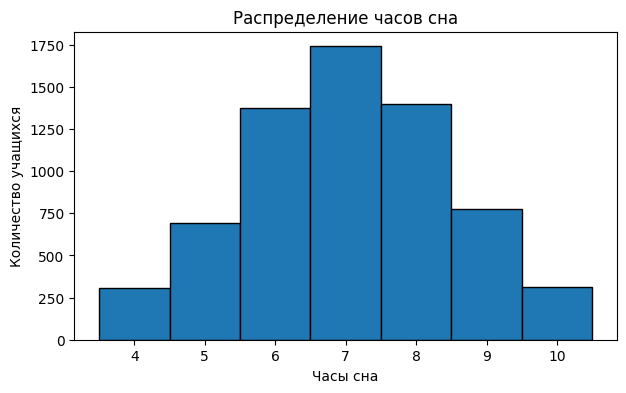

Форма приближенно колоколообразная, но данные дискретные и ограничены 4–10 часами; говорить о строгой нормальности нельзя.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['Sleep_Hours'], bins=np.arange(3.5, 11.5, 1), edgecolor='black')
ax.set(xlabel='Часы сна', ylabel='Количество учащихся', title='Распределение часов сна')
plt.show()
print('Форма приближенно колоколообразная, но данные дискретные и ограничены 4–10 часами;'
      ' говорить о строгой нормальности нельзя.')


2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

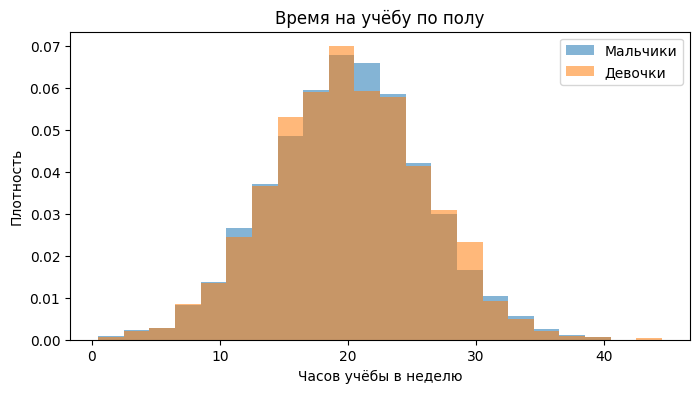

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(df['Hours_Studied'].min() - 0.5, df['Hours_Studied'].max() + 1.5, 2)
for gender, label in [('Male', 'Мальчики'), ('Female', 'Девочки')]:
    values = df.loc[df['Gender'] == gender, 'Hours_Studied']
    ax.hist(values, bins=bins, alpha=0.55, label=label, density=True)
ax.set(xlabel='Часов учёбы в неделю', ylabel='Плотность', title='Время на учёбу по полу')
ax.legend()
plt.show()


3. Как зависит результат конечного экзамена от результата первого экзамена

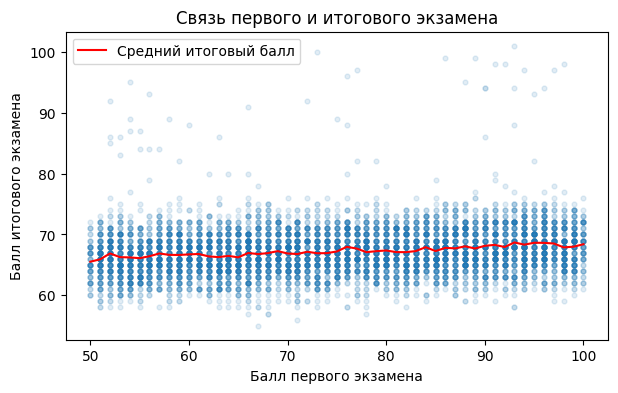

Корреляция: 0.175


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df['Previous_Scores'], df['Exam_Score'], alpha=0.13, s=12)
by_previous = df.groupby('Previous_Scores')['Exam_Score'].mean()
ax.plot(by_previous.index, by_previous.values, color='red', label='Средний итоговый балл')
ax.set(xlabel='Балл первого экзамена', ylabel='Балл итогового экзамена',
       title='Связь первого и итогового экзамена')
ax.legend()
plt.show()
print('Корреляция:', round(df['Previous_Scores'].corr(df['Exam_Score']), 3))


4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

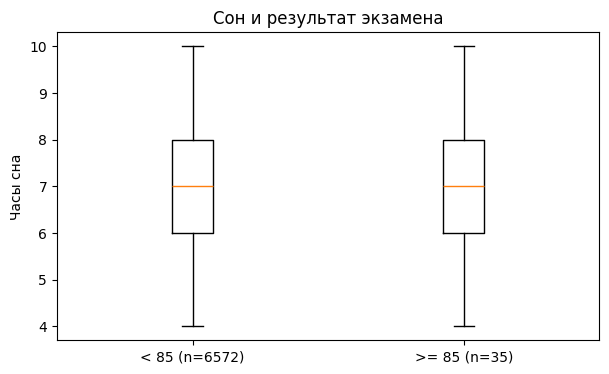

Учащихся с >=85: 35 ; при малой группе выводы ненадёжны.


In [ ]:
low = df.loc[df['Exam_Score'] < 85, 'Sleep_Hours']
high = df.loc[df['Exam_Score'] >= 85, 'Sleep_Hours']
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([low, high], tick_labels=[f'< 85 (n={len(low)})', f'>= 85 (n={len(high)})'])
ax.set(ylabel='Часы сна', title='Сон и результат экзамена')
plt.show()
print('Учащихся с >=85:', len(high), '; при малой группе выводы ненадёжны.')


5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

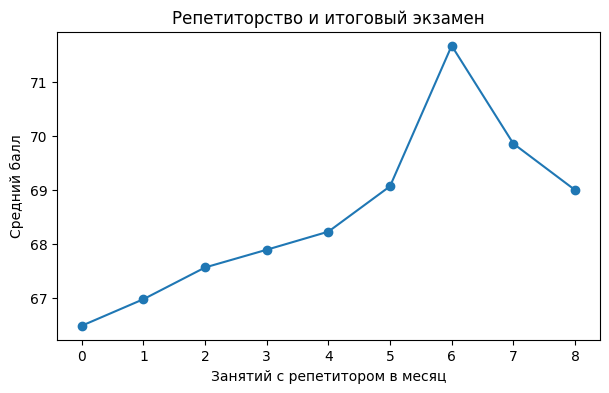

,mean,count
Tutoring_Sessions,,
0,66.489755,1513
1,66.980266,2179
2,67.567010,1649
3,67.894737,836
4,68.229236,301
5,69.067961,103
6,71.666667,18
7,69.857143,7
8,69.000000,1


Корреляция: 0.157
Наличие связи не означает доказанного причинного влияния.


In [ ]:
tutor_scores = df.groupby('Tutoring_Sessions')['Exam_Score'].agg(['mean', 'count'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tutor_scores.index, tutor_scores['mean'], marker='o')
ax.set(xlabel='Занятий с репетитором в месяц', ylabel='Средний балл',
       title='Репетиторство и итоговый экзамен')
plt.show()
display(tutor_scores)
print('Корреляция:', round(df['Tutoring_Sessions'].corr(df['Exam_Score']), 3))
print('Наличие связи не означает доказанного причинного влияния.')


6. Как физическая активность влияет на успеваемость?

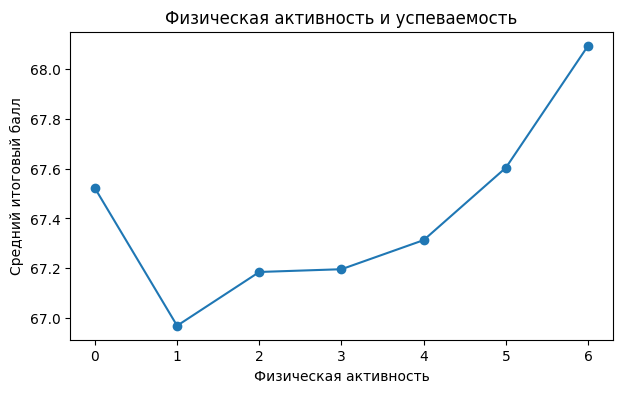

,mean,count
Physical_Activity,,
0,67.521739,46
1,66.969121,421
2,67.185003,1627
3,67.196071,2545
4,67.313016,1575
5,67.603878,361
6,68.093750,32


In [ ]:
activity_summary = df.groupby('Physical_Activity')['Exam_Score'].agg(['mean', 'count'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(activity_summary.index, activity_summary['mean'], marker='o')
ax.set(xlabel='Физическая активность', ylabel='Средний итоговый балл',
       title='Физическая активность и успеваемость')
plt.show()
display(activity_summary)


7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

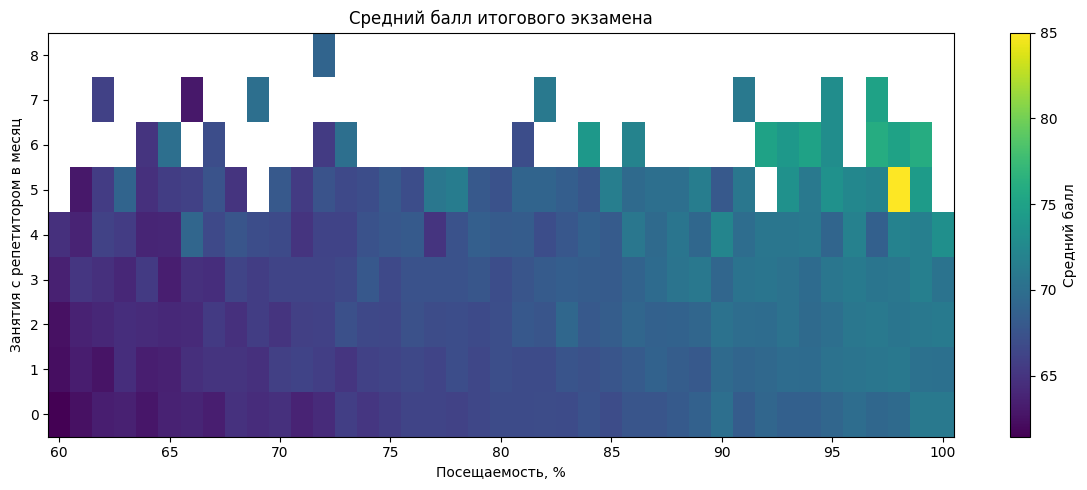

In [ ]:
heatmap_data = df.pivot_table(index='Tutoring_Sessions', columns='Attendance',
                              values='Exam_Score', aggfunc='mean')
fig, ax = plt.subplots(figsize=(12, 5))
image = ax.imshow(heatmap_data.to_numpy(), aspect='auto', origin='lower', cmap='viridis')
col_indices = np.linspace(0, len(heatmap_data.columns) - 1, 9, dtype=int)
ax.set_xticks(col_indices, heatmap_data.columns[col_indices])
ax.set_yticks(np.arange(len(heatmap_data.index)), heatmap_data.index)
ax.set(xlabel='Посещаемость, %', ylabel='Занятия с репетитором в месяц',
       title='Средний балл итогового экзамена')
fig.colorbar(image, ax=ax, label='Средний балл')
plt.tight_layout()
plt.show()
